# KNN with iris dataset


In [1]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
iris = load_iris()
X = iris.data      
y = iris.target     
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
k = 3
knn = KNeighborsClassifier(n_neighbors=k)
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print("KNN Classifier")
print("K =", k)
print("Accuracy =", accuracy)
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
new_flower = [[5.1, 3.5, 1.4, 0.2]]
prediction = knn.predict(new_flower)
print("\nPredicted class:", iris.target_names[prediction][0])

KNN Classifier
K = 3
Accuracy = 1.0

Confusion Matrix:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]

Predicted class: setosa


# KNN from scratch

Step-by-step distance demo (point0 -> point1):
  p0=(1, 2), p1=(2, 3)
  distance = 1.4142

LOOCV accuracy per k:
  k=3: accuracy = 100.00%
  k=4: accuracy = 100.00%
  k=5: accuracy = 100.00%

Optimal k = 3 (accuracy = 100.00%)


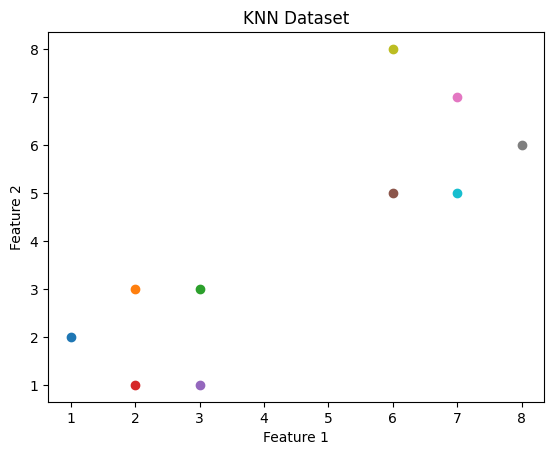

In [17]:
import matplotlib.pyplot as plt
dataset = [
    (1, 2, 0),
    (2, 3, 0),
    (3, 3, 0),
    (2, 1, 0),
    (3, 1, 0),
    (6, 5, 1),
    (7, 7, 1),
    (8, 6, 1),
    (6, 8, 1),
    (7, 5, 1),
]
def euclidean_distance(p1, p2):
    total = 0
    for i in range(len(p1)):       
        diff = p1[i] - p2[i]         
        squared = diff * diff        
        total = total + squared       
    distance = total ** 0.5           
    return distance
def knn_predict(train_data, query_point, k):
    distances = []
    for row in train_data:
        point = row[:-1]
        label = row[-1]
        d = euclidean_distance(point, query_point)
        distances.append((d, label))
    n = len(distances)
    for i in range(n):
        for j in range(0, n - i - 1):
            if distances[j][0] > distances[j + 1][0]:
                distances[j], distances[j + 1] = distances[j + 1], distances[j]
    k_nearest = distances[:k]
    votes = {}
    for d, label in k_nearest:
        votes[label] = votes.get(label, 0) + 1
    best_label, best_count = None, -1
    for label, count in votes.items():
        if count > best_count:
            best_label, best_count = label, count
    return best_label, k_nearest
def loocv_accuracy(data, k):
    correct = 0
    for i in range(len(data)):
        test_point = data[i]
        train_data = data[:i] + data[i + 1:]
        pred, _ = knn_predict(train_data, test_point[:-1], k)
        if pred == test_point[-1]:
            correct += 1
    return correct / len(data)
if __name__ == "__main__":
    print("Step-by-step distance demo (point0 -> point1):")
    print(f"  p0={dataset[0][:-1]}, p1={dataset[1][:-1]}")
    d = euclidean_distance(dataset[0][:-1], dataset[1][:-1])
    print(f"  distance = {d:.4f}\n")
    print("LOOCV accuracy per k:")
    results = {}
    for k in (3, 4, 5):
        acc = loocv_accuracy(dataset, k)
        results[k] = acc
        print(f"  k={k}: accuracy = {acc:.2%}")
    best_k = max(results, key=lambda kk: results[kk])
    print(f"\nOptimal k = {best_k} (accuracy = {results[best_k]:.2%})")
for row in dataset:
    plt.scatter(row[0],row[1])
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("KNN Dataset")
plt.show()